<div align="center">

# Université Paris 1 Panthéon-Sorbonne

### M1 MIAGE SBI

### Atelier Python pour Data Science (INF4)

<br>

## Séance 4

#### Exploration, visualisation et jointures

<br>

### Groupe G12

#### Ryles AIT-MOHAMMED<br>Aliou DIALLO<br>Meryem BERRAMOU<br>Rita HDIDOU<br>Shirel MARCIANO

<br>

##### Année universitaire 2026-2027

</div>

---

# M1-INF4 — Python Workshop for Data Analysis
## Session 4 — Explore, visualise and connect data

A useful figure answers a question. A reliable answer also needs the right observation unit, a comparable period and checked data.

**By the end, you should be able to:** select and build six reusable chart types, explain a finding and its limits, and join two tables without silently losing or multiplying observations.

Use the same workflow throughout: **question → observation unit → checks and aggregation → chart → interpretation**. These are the tools for the final group case study.

### Working files and contexts
Place the notebook in `notebooks/`, beside the course `data/` folder. You need `temperatures.csv`, `support_tickets.csv` and `support_sites.csv`.

| Table | One row represents | Main fields |
|---|---|---|
| Temperatures | One city–country–month | date, city, country, avg_temp_c (°C) |
| Support tickets | One resolved support ticket | ticket_id, date (opening day), site_id, channel, resolution_h (hours) |
| Support sites | One support site | site_id, site_name, region |

The support data is **synthetic training data**: durations are illustrative, three measurements are missing, and one site identifier is deliberately absent from the site reference. It describes resolved tickets only, not the full backlog. Dates identify the study windows; they are not a current operational report.

Examples are complete. Exercises require your own code and interpretation. Run from top to bottom; an unfinished exercise will not prevent the later guided examples from running.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

DATA_DIR = Path("../data") if Path("../data/support_tickets.csv").exists() else Path("data")
OUTPUT_DIR = Path("figures")
OUTPUT_DIR.mkdir(exist_ok=True)
tickets = pd.read_csv(DATA_DIR / "support_tickets.csv", parse_dates=["date"])
sites = pd.read_csv(DATA_DIR / "support_sites.csv")
temps = pd.read_csv(DATA_DIR / "temperatures.csv", index_col=0, parse_dates=["date"])
BLUE, ORANGE, TEAL = "#00386E", "#D97706", "#007F73"
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
display(tickets.head())
display(sites)

,ticket_id,date,site_id,channel,resolution_h
0,1,2025-03-03,S1,Phone,0.80
1,2,2025-03-03,S1,Email,7.03
2,3,2025-03-03,S1,Phone,0.47
3,4,2025-03-03,S2,Phone,1.62
4,5,2025-03-03,S2,Phone,1.48


,site_id,site_name,region
0,S1,North desk,North
1,S2,Central desk,Centre
2,S3,South desk,South


## 1. Ask a question before plotting

A dashboard designer, business analyst or information-systems manager needs to distinguish **volume**, **typical value**, **variability** and **coverage**.

For support tickets, a lower median duration does not prove that a channel is more efficient: it may handle easier cases. Count the observations and available measurements before comparing.

In [2]:
assert tickets["ticket_id"].is_unique
assert tickets["resolution_h"].dropna().ge(0).all()
display(tickets.isna().sum())
channel_summary = tickets.groupby("channel")["resolution_h"].agg(["size", "count", "mean", "median"])
display(channel_summary)
print("Window:", tickets["date"].min().date(), "to", tickets["date"].max().date())

ticket_id       0
date            0
site_id         0
channel         0
resolution_h    3
dtype: int64

,size,count,mean,median
channel,,,,
Email,98,98,4.623367,4.08
Phone,106,103,1.814175,1.52
Portal,99,99,2.800404,2.18


Window: 2025-03-03 to 2025-03-28


### A selective chart chooser

| Question | Chart | What must be prepared? |
|---|---|---|
| Which category has more observations? | Bar chart | One value per category |
| How does an indicator evolve? | Line chart | Ordered dates, consistent periods |
| How are individual values distributed? | Histogram | A numeric series, not precomputed category counts |
| How do groups differ in spread? | Boxplot | Numeric observations within each group |
| Are two numeric variables associated? | Scatter plot | Paired measurements on the same observational unit |
| Where are high/low values in a matrix? | Heatmap | An explicitly defined row × column matrix |

Do not add every chart to a report. Choose the smallest set that answers the question.

### The reusable Matplotlib pattern

`fig` is the whole figure; `ax` is one plotting area. Use `ax` to draw and label, then save with `fig.savefig(...)`.

- **Title:** what is measured, for whom, and over which period. Use a claim only after checking it.
- **Axis labels:** variable names meaningful to the reader, with units.
- **Legend:** explains multiple series, colours or markers. One series with labelled categories usually needs no legend.
- **Colourbar:** maps colour to numeric values in a heatmap; it is not a category legend.
- **Caption / interpretation:** source context, missingness and limits when relevant.

A reusable skeleton (replace the placeholders):
```python
fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
# ax.<plotting_method>(...)
ax.set(title="Indicator — population and period", xlabel="Variable (unit)", ylabel="Variable (unit)")
# ax.legend(title="Series")  # only for multiple labelled series
fig.savefig(OUTPUT_DIR / "figure.png", dpi=150, bbox_inches="tight")
plt.show()
```
Keep the same colours for the same groups across figures. Avoid 3D decoration and red/green-only distinctions. Use readable labels and restrained grids.

## 2. Bar chart — compare categories

**Business use:** ticket volumes by channel, costs by department, sales by product.

**What goes where:** category on the vertical axis for horizontal bars; its count or aggregate on the horizontal axis. Aggregate first. Sort by value unless categories have a natural order.

**Particularity:** bar length encodes magnitude, so start the quantitative axis at zero. Use a consistent colour for one series; category labels replace a redundant legend.

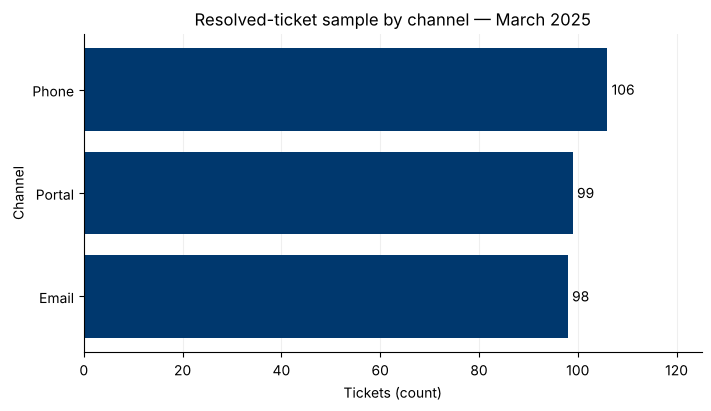

In [3]:
volume = tickets.groupby("channel").size().sort_values()
fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
bars = ax.barh(volume.index, volume.values, color=BLUE)
ax.bar_label(bars, padding=3)
ax.set(title="Resolved-ticket sample by channel — March 2025", xlabel="Tickets (count)", ylabel="Channel")
ax.set_xlim(0, volume.max() * 1.18)
ax.grid(axis="x", alpha=.2)
ax.set_axisbelow(True)
plt.show()

**Read it:** this is a count of tickets in the supplied resolved-ticket sample, not demand from every customer. Counts do not measure speed, cost or quality.

**Quick check:** why would `tickets["resolution_h"].count()` give a different total from `len(tickets)`? Discuss before continuing.

## 3. Line chart — follow a time series

**Business use:** weekly revenue, service load, energy use, monthly temperatures.

**What goes where:** chronological time on x; one numeric indicator with its unit on y. A line connects successive observations, so order dates and use a consistent time grid.

**Particularity:** unlike bars, the y-axis need not always start at zero, but limits must be explicit and not chosen to exaggerate a difference. Missing observations should create a gap, not a false zero. Multiple cities need labelled lines and a legend.

,size,count
city,,
London,12,12
Paris,12,12
Rome,12,12


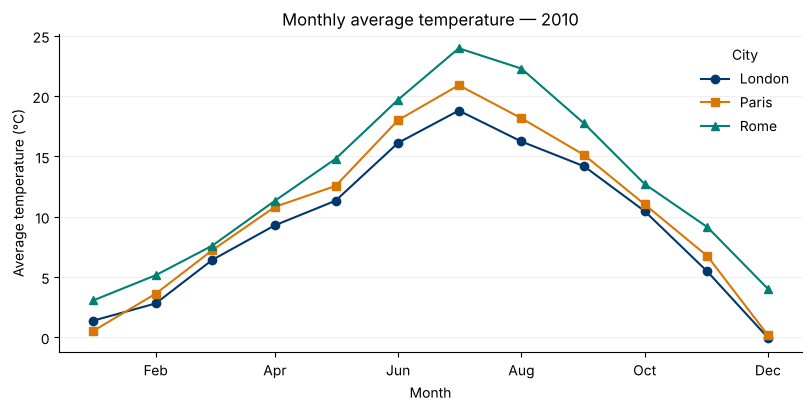

In [4]:
cities = ["London", "Paris", "Rome"]
period = temps.loc[temps["city"].isin(cities) & temps["date"].dt.year.eq(2010)].copy()
assert not period.duplicated(["city", "date"]).any()
display(period.groupby("city")["avg_temp_c"].agg(["size", "count"]))
months = pd.date_range("2010-01-01", periods=12, freq="MS")
fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
for city, colour, marker in zip(cities, [BLUE, ORANGE, TEAL], ["o", "s", "^"]):
    series = period.loc[period["city"].eq(city)].set_index("date")["avg_temp_c"].reindex(months)
    ax.plot(series.index, series.values, color=colour, marker=marker, label=city)
ax.set(title="Monthly average temperature — 2010", xlabel="Month", ylabel="Average temperature (°C)")
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.legend(title="City", frameon=False)
ax.grid(axis="y", alpha=.2)
plt.show()

`reindex(months)` makes the expected monthly grid explicit: an absent month becomes missing and breaks the line. This is not imputation. Comparing the same year controls the displayed period; one year does not establish a long-term climate trend.

## 4. Histogram — understand a numeric distribution

**Business use:** resolution durations, transaction amounts, delivery delays.

**What goes where:** numeric value ranges (bins) on x, number of observations on y. The input is the individual measurements. Adjacent bins represent intervals, not named categories.

**Particularity:** changing the bins changes the visible shape. Name the y-axis correctly: counts are not percentages or probability density. Use the same bin boundaries when comparing groups.

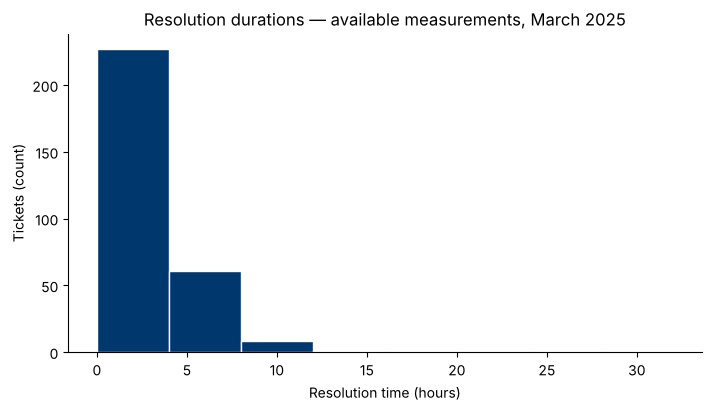

In [5]:
durations = tickets["resolution_h"].dropna()
bin_edges = np.arange(0, 36, 4)
fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
ax.hist(durations, bins=bin_edges, color=BLUE, edgecolor="white")
ax.set(title="Resolution durations — available measurements, March 2025", xlabel="Resolution time (hours)", ylabel="Tickets (count)")
plt.show()

The first chart uses equal-width 4-hour bins. The next uses 2-hour bins: compare which details become visible without changing the data. Missing durations are excluded; unusually long durations remain. Avoid comparing separate histograms with different bin boundaries or sample sizes without explaining the difference.

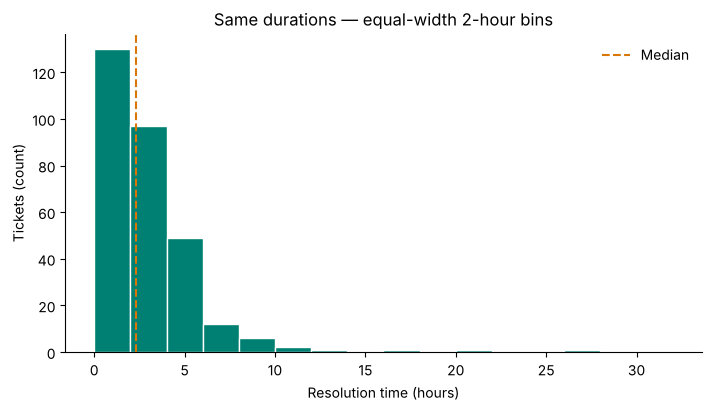

In [6]:
fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
ax.hist(durations, bins=np.arange(0, 34, 2), color=TEAL, edgecolor="white")
ax.axvline(durations.median(), color=ORANGE, linestyle="--", label="Median")
ax.set(title="Same durations — equal-width 2-hour bins", xlabel="Resolution time (hours)", ylabel="Tickets (count)")
ax.legend(frameon=False)
plt.show()

## 5. Boxplot — compare centre and spread

**Business use:** compare resolution times by channel or delivery delays by provider.

**What goes where:** groups on x, numeric measurements on y. Supply each group's observations, not just its mean.

**Particularity:** the middle line is the median; the box extends from Q1 to Q3. With the default rule, whiskers extend to the most extreme observed values within 1.5 × IQR of the quartiles. Points beyond them are flagged observations, not automatically errors. Show sample sizes; a boxplot hides detail about distribution shape.

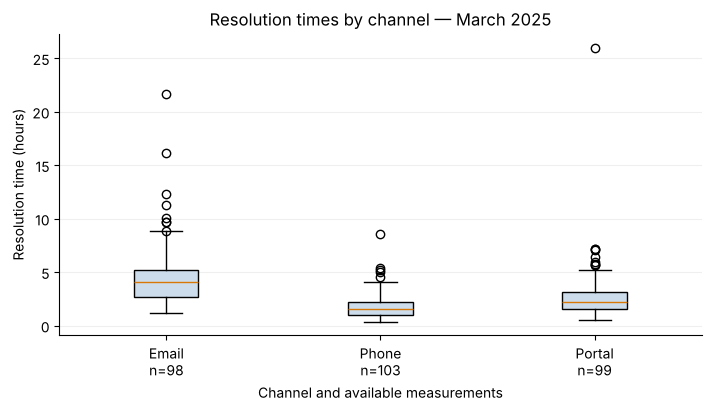

In [7]:
channels = ["Email", "Phone", "Portal"]
groups = [tickets.loc[tickets["channel"].eq(c), "resolution_h"].dropna() for c in channels]
fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
ax.boxplot(groups, patch_artist=True, boxprops={"facecolor": "#CCDCEA"}, medianprops={"color": ORANGE})
ax.set_xticks(range(1, len(channels) + 1), [f"{c}\nn={len(g)}" for c, g in zip(channels, groups)])
ax.set(title="Resolution times by channel — March 2025", xlabel="Channel and available measurements", ylabel="Resolution time (hours)")
ax.grid(axis="y", alpha=.2)
plt.show()

## Group problem 1 — Does more activity mean slower service?

A manager says: **“The busiest channel must also be the slowest.”** Investigate using `tickets`.

1. Calculate ticket count, available duration count, mean and median by channel.
2. Choose **two** complementary charts from those already introduced: one for volume and one for duration. Explain your choice before coding.
3. Give each figure a title, units and readable group labels; disclose missing durations.
4. Write three sentences: whether the sample supports the claim, what the mean and median tell you, and one limitation preventing a claim about efficiency.

Do not remove a long duration merely because it appears outside a boxplot whisker. **Deliverable:** summary table, two figures and your interpretation. Each group member must be able to explain the observation unit and denominator.

,ticket_count,duration_count,mean_hours,median_hours
channel,,,,
Email,98,98,4.62,4.08
Phone,106,103,1.81,1.52
Portal,99,99,2.80,2.18


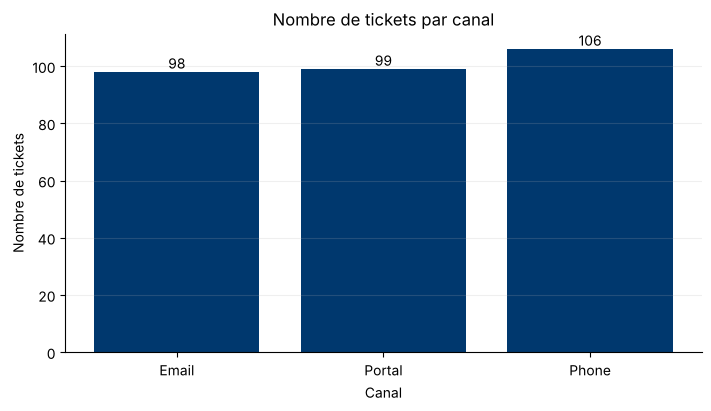

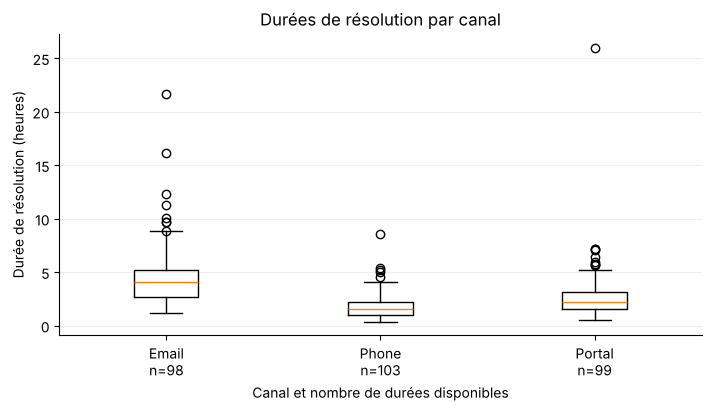

Durées manquantes par canal :


channel
Email     0
Phone     3
Portal    0
Name: resolution_h, dtype: int64

Total de durées manquantes : 3


In [8]:
# Your code here

# 1) Résumé par canal
channel_summary = (
    tickets.groupby("channel")["resolution_h"]
    .agg(
        ticket_count="size",
        duration_count="count",
        mean_hours="mean",
        median_hours="median"
    )
    .round(2)
)

display(channel_summary)

# 2) Graphique 1. Un diagramme en barres pour comparer le nombre de tickets. Il montre le canal le plus actif.
volume = tickets.groupby("channel").size().sort_values()
fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
bars = ax.bar(volume.index, volume.values, color=BLUE)
ax.bar_label(bars)
ax.set(
    title="Nombre de tickets par canal",
    xlabel="Canal",
    ylabel="Nombre de tickets"
)
ax.grid(axis="y", alpha=0.2)
plt.show()

# Graphique 2. Un boxplot pour comparer les durées.
channels = ["Email", "Phone", "Portal"]
groups = [
    tickets.loc[tickets["channel"].eq(channel), "resolution_h"].dropna()
    for channel in channels
]

fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
ax.boxplot(groups)
ax.set_xticks(
    range(1, len(channels) + 1),
    [f"{channel}\nn={len(group)}" for channel, group in zip(channels, groups)]
)
ax.set(
    title="Durées de résolution par canal",
    xlabel="Canal et nombre de durées disponibles",
    ylabel="Durée de résolution (heures)"
)
ax.grid(axis="y", alpha=0.2)
plt.show()

#3)

# Durées manquantes par canal
missing_durations = tickets.groupby("channel")["resolution_h"].apply(
    lambda values: values.isna().sum()
)

print("Durées manquantes par canal :")
display(missing_durations)

print(
    "Total de durées manquantes :",
    tickets["resolution_h"].isna().sum()
)



**Your interpretation:** write your answer here.

4) Le canal le plus actif est Phone avec 106 tickets, mais il n’est pas le plus lent, car c'est Email qui a la moyenne (4,62 h) et la médiane (4,08 h) les plus élevées. La moyenne représente la durée moyenne, tandis que la médiane représente la durée centrale et est moins influencée par les valeurs extrêmes. Cette comparaison ne prouve pas qu’Email est moins efficace, car les canaux peuvent traiter des types de tickets ou des niveaux de difficulté différents.


## 6. Scatter plot — examine a relationship

**Business use:** workload versus delay, store size versus sales, cost versus volume.

**What goes where:** explanatory/context variable on x and response indicator on y. Both must describe the same unit. Here, **one point is one site-day**, not one ticket.

**Particularity:** a cloud reveals association and unusual pairs, not causation. Use transparency for overlaps. Do not connect unrelated points. Colour needs a legend only when it encodes a group; avoid colour without meaning.

,site_id,date,size,count,mean
0,S1,2025-03-03,3,3,2.766667
1,S1,2025-03-04,6,6,4.691667
2,S1,2025-03-05,6,6,1.958333
3,S1,2025-03-06,6,6,2.438333
4,S1,2025-03-07,4,3,3.736667


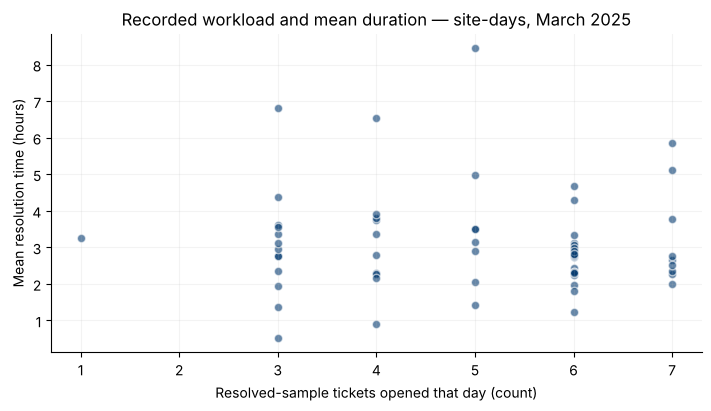

In [9]:
daily = tickets.groupby(["site_id", "date"])["resolution_h"].agg(["size", "count", "mean"]).reset_index()
display(daily.head())
fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
ax.scatter(daily["size"], daily["mean"], color=BLUE, alpha=.6, edgecolors="white")
ax.set(title="Recorded workload and mean duration — site-days, March 2025", xlabel="Resolved-sample tickets opened that day (count)", ylabel="Mean resolution time (hours)")
ax.grid(alpha=.15)
plt.show()

Read the pattern without inventing a causal explanation. The x values are discrete, so points may overlap vertically. The y values average different numbers of available durations. This does not show the time each ticket spent waiting or the site's entire workload.

## 7. Heatmap — scan a matrix

**Business use:** load by site and weekday, product performance by month, a matrix of indicators.

**What goes where:** rows identify one dimension, columns another; colour represents one numeric measure. Start by constructing the matrix and inspecting it.

`pivot_table(index=..., columns=..., values=..., aggfunc=...)` groups records into a matrix. Unlike a simple `pivot`, it can aggregate several observations in a cell. Choose the aggregation explicitly.

**Particularity:** use a sequential colour scale for low-to-high values, and a labelled colourbar. A diverging scale needs a meaningful centre (such as zero deviation). Missing is not zero.

weekday,0,1,2,3,4
site_id,,,,,
S1,19.0,18.0,20.0,23.0,21.0
S2,15.0,23.0,22.0,21.0,22.0
S3,17.0,20.0,20.0,20.0,21.0
S99,NaN,NaN,NaN,NaN,1.0


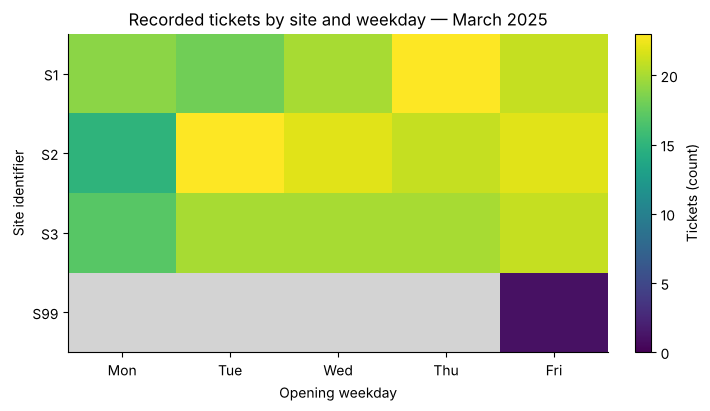

In [10]:
heat_data = tickets.copy()
heat_data["weekday"] = heat_data["date"].dt.dayofweek  # Monday=0
matrix = heat_data.pivot_table(index="site_id", columns="weekday", values="ticket_id", aggfunc="count").reindex(columns=range(5))
display(matrix)
colourmap = plt.get_cmap("viridis").copy()
colourmap.set_bad("lightgrey")
fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
im = ax.imshow(np.ma.masked_invalid(matrix.to_numpy(dtype=float)), aspect="auto", cmap=colourmap, vmin=0)
ax.set_xticks(range(5), ["Mon", "Tue", "Wed", "Thu", "Fri"])
ax.set_yticks(range(len(matrix)), matrix.index)
ax.set(title="Recorded tickets by site and weekday — March 2025", xlabel="Opening weekday", ylabel="Site identifier")
fig.colorbar(im, ax=ax, label="Tickets (count)")
plt.show()

Grey means no observed combination in the supplied extract. It must not be silently interpreted as confirmed zero demand. The date window contains four occurrences of each weekday; totals across weekdays therefore cover equal numbers of dates, but this is still only a resolved-ticket sample. The unexpected `S99` row is a cue to check the site reference, not to hide it.

**Quick check:** why would a rainbow of unrelated category colours be unsuitable for the magnitude scale?

## 8. Connect tables with a checked join

A familiar database idea: tickets are a **fact table** (many rows per site), and `sites` is a **reference table** (one row per site). `site_id` is the join key; row positions are not a join key.

| Choice | Result |
|---|---|
| `how="left"` | Keep all ticket rows; unmatched reference fields become missing |
| `how="inner"` | Keep only tickets whose key matches a reference row |
| `validate="many_to_one"` | Require unique keys on the right; stop if the reference can multiply tickets |
| `indicator=True` | Add `_merge` so unmatched rows can be audited |

Check missing keys before joining: pandas can match missing keys to each other, unlike usual SQL null behaviour. Make key types and representations consistent. Never choose a join only because its result “looks right”.

In [11]:
assert tickets["site_id"].notna().all()
assert sites["site_id"].notna().all()
assert sites["site_id"].is_unique
joined = tickets.merge(sites, on="site_id", how="left", validate="many_to_one", indicator=True)
assert len(joined) == len(tickets)
assert joined["ticket_id"].is_unique
display(joined["_merge"].value_counts())
display(joined.loc[joined["_merge"].eq("left_only"), ["ticket_id", "site_id"]])

_merge
both          302
left_only       1
right_only      0
Name: count, dtype: int64

,ticket_id,site_id
302,303,S99


In [12]:
matched_only = tickets.merge(sites, on="site_id", how="inner", validate="many_to_one")
print("Left join rows:", len(joined))
print("Inner join rows:", len(matched_only))
print("Tickets excluded by the inner join:", len(tickets) - len(matched_only))

# Deliberate reference error: catch it rather than silently multiplying rows.
bad_sites = pd.concat([sites, sites.iloc[[0]]], ignore_index=True)
try:
    tickets.merge(bad_sites, on="site_id", how="left", validate="many_to_one")
except pd.errors.MergeError:
    print("Stopped: the site reference is not unique. Investigate before joining.")

Left join rows: 303
Inner join rows: 302
Tickets excluded by the inner join: 1
Stopped: the site reference is not unique. Investigate before joining.


The unmatched ticket remains visible with a left join. An inner join silently excludes it unless you audit the row count. `validate` checks key multiplicity, not the business truth of a site name.

When both tables contain a non-key column with the same name, pandas adds suffixes (for example `_x`, `_y`). Resolve what those fields mean rather than discarding one arbitrarily.

## Group problem 2 — Build a small decision brief

A service manager wants to know **which sites deserve further investigation for long resolution times**. Use the three support tables/objects already available: `tickets`, `sites`, and the checked join approach.

1. Perform a left join with `validate="many_to_one"` and `indicator=True`. Report matched and unmatched ticket counts. Do not invent a name for an unknown site.
2. Keep the unmatched rows in a separate review table. For matched rows, calculate ticket count, available duration count, median and mean resolution hours by site name.
3. Choose **two complementary charts** from the six types. State the question and observation unit for each. At least one must show dispersion or a distribution, not just a ranking of averages.
4. Write a four-sentence decision brief: an observation, supporting evidence, a limitation and a proposed next investigation. Do not equate the highest average with the worst team.
5. Export the summary as CSV (`index=False`) and one figure as PNG. Report how many rows were excluded from the named-site comparison.

**Deliverable:** reproducible code, join audit, summary, two charts, brief. Your choice of chart is assessed by its relevance and clarity, not decoration. Review the full result together.

Tickets avec site connu : 302
Tickets avec site inconnu : 1

Table de verification des sites inconnus :


,ticket_id,site_id,date,resolution_h
302,303,S99,2025-03-28,3.26


,site_name,ticket_count,duration_count,median_hours,mean_hours
0,South desk,98,97,2.38,3.00
1,North desk,101,99,2.31,3.01
2,Central desk,103,103,2.13,3.15


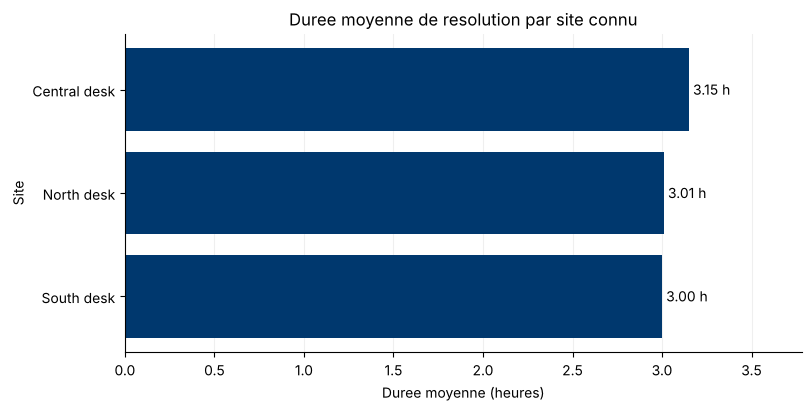

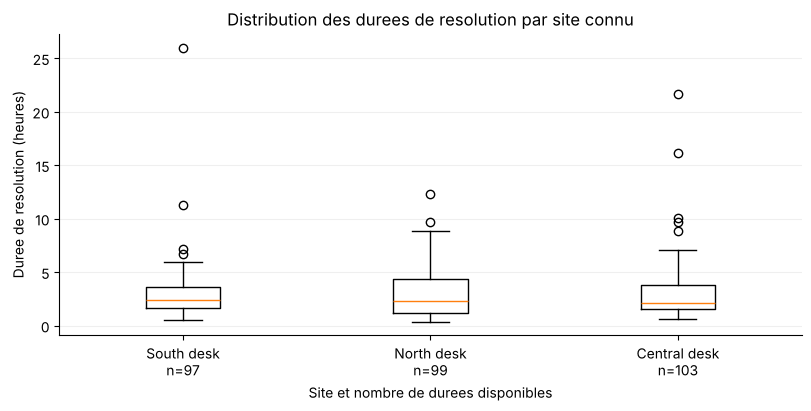

Lignes exclues de la comparaison par site nomme : 1


In [13]:
# Your code here


# 1) Jointure controlee et audit des correspondances
joined = tickets.merge(
    sites,
    on="site_id",
    how="left",
    validate="many_to_one",
    indicator=True,
)

assert len(joined) == len(tickets)

join_counts = joined["_merge"].value_counts()
print("Tickets avec site connu :", join_counts.get("both", 0))
print("Tickets avec site inconnu :", join_counts.get("left_only", 0))

review = joined.loc[
    joined["_merge"].eq("left_only"),
    ["ticket_id", "site_id", "date", "resolution_h"],
].copy()

print("\nTable de verification des sites inconnus :")
display(review)

# 2) Resume des tickets associes a un site connu
matched = joined.loc[joined["_merge"].eq("both")].copy()
site_summary = (
    matched.groupby("site_name")["resolution_h"]
    .agg(
        ticket_count="size",
        duration_count="count",
        median_hours="median",
        mean_hours="mean",
    )
    .sort_values("median_hours", ascending=False)
    .round(2)
    .reset_index()
)

display(site_summary)

# Graphique 1. Diagramme en barres des moyennes
# Question. Quels sites connus ont les durées moyennes
# de résolution les plus élevées ?
# Unité d'observation. Un ticket avec une durée disponible,
# résumé par site

fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
ordered = site_summary.sort_values("mean_hours")
bars = ax.barh(ordered["site_name"], ordered["mean_hours"], color=BLUE)
ax.bar_label(bars, fmt="%.2f h", padding=3)
ax.set(
    title="Duree moyenne de resolution par site connu",
    xlabel="Duree moyenne (heures)",
    ylabel="Site",
)
ax.set_xlim(0, ordered["mean_hours"].max() * 1.2)
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)
OUTPUT_DIR.mkdir(exist_ok=True)
fig.savefig(OUTPUT_DIR / "site_mean_resolution.png", dpi=150, bbox_inches="tight")
plt.show()

# Graphique 2. Boxplot
# Question. Comment la distribution et la dispersion des
# durées de résolution varient-elles selon le site ?
# Unité d'observation. Une durée disponible par ticket.
site_names = site_summary["site_name"].tolist()
groups = [
    matched.loc[matched["site_name"].eq(site_name), "resolution_h"].dropna()
    for site_name in site_names
]

fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
ax.boxplot(groups)
ax.set_xticks(
    range(1, len(site_names) + 1),
    [f"{site_name}\nn={len(group)}" for site_name, group in zip(site_names, groups)],
)
ax.set(
    title="Distribution des durees de resolution par site connu",
    xlabel="Site et nombre de durees disponibles",
    ylabel="Duree de resolution (heures)",
)
ax.grid(axis="y", alpha=0.2)
plt.show()

# 5) Exports
site_summary.to_csv(OUTPUT_DIR / "site_resolution_summary.csv", index=False)
print("Lignes exclues de la comparaison par site nomme :", len(review))




**Your interpretation:** write your answer here.

**4.** 
Central desk présente la moyenne de résolution la plus élevée avec 3,15 heures, tandis que South desk présente la médiane la plus élevée avec 2,38 heures. Les écarts entre les sites restent faibles et ces résultats reposent sur 302 tickets associés à un site connu, dont 299 disposent d’une durée de résolution. La comparaison est limitée par les durées manquantes, par le ticket S99 exclu de la comparaison par site nommé et par le fait que les sites peuvent traiter des tickets de difficulté différente. Il faudrait analyser les types de tickets et recueillir davantage de données avant de conclure qu’un site est moins performant.

## 9. A reusable delivery check

Before sharing a figure or recommendation:
- State the question and what one row or point represents.
- Check the period, population, units, missingness and join coverage.
- Choose an aggregation and chart that match the question.
- Use meaningful labels, a readable scale and only necessary legends.
- Report evidence and a limitation; separate observation from explanation.
- Restart the kernel and run the notebook from the top; save the figure and its underlying summary.

The final case study combines loading, cleaning, checked joins, analysis, figures and a justified recommendation. The essential techniques have now been introduced; you will choose how to combine them.

### OPTIONAL / IF TIME ALLOWS — Put a claim to the test
Choose one chart in this notebook. Make a deliberately poor presentation (for example, truncated bars or an unexplained colour scale). Then repair it. Explain exactly how the first version could mislead a reader. Do not use the misleading version in a report.